# Differentially private fraud counts by age band

How accurately can a shared report show the number of cards with at least one fraud-labeled transaction in each age band? This demonstration uses the project's [simulated transaction dataset](https://www.kaggle.com/datasets/kartik2112/fraud-detection) and compares exact counts with noisy counts at three privacy budgets. The model is outside the scope of this reporting experiment.

Run the notebook with pandas, NumPy, and Matplotlib installed and `data/fraudTrain.csv` in the project.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

data_path = Path("data/fraudTrain.csv")
if not data_path.is_file():
    data_path = Path("../data/fraudTrain.csv")

transactions = pd.read_csv(
    data_path,
    usecols=["cc_num", "dob", "is_fraud"],
    dtype={"cc_num": "string"},
    parse_dates=["dob"],
)
if transactions[["cc_num", "dob"]].isna().any().any():
    raise ValueError("Every transaction must have a card identifier and birth date.")
if not transactions["is_fraud"].isin([0, 1]).all():
    raise ValueError("Fraud labels must be 0 or 1.")

cards = transactions.groupby("cc_num").agg(
    dob=("dob", "min"),
    dob_count=("dob", "nunique"),
    had_fraud=("is_fraud", "max"),
)
if not cards["dob_count"].eq(1).all():
    raise ValueError("Each card must have one consistent birth date.")

# Use a fixed date so a card stays in the same band across transactions.
reference_date = pd.Timestamp("2019-01-01")
dob = cards["dob"].dt
birthday_pending = (dob.month * 100 + dob.day) > (
    reference_date.month * 100 + reference_date.day
)
age = reference_date.year - dob.year - birthday_pending.astype(int)
age_bins = [0, 20, 30, 40, 50, 60, 70, 80, np.inf]
age_labels = ["Under 20", "20-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]
cards["age_band"] = pd.cut(age, age_bins, labels=age_labels, right=False)
if cards["age_band"].isna().any():
    raise ValueError("Every card must fit one of the fixed age bands.")

exact_counts = (
    cards.loc[cards["had_fraud"].eq(1), "age_band"]
    .value_counts(sort=False)
    .reindex(age_labels, fill_value=0)
)
assert exact_counts.sum() == cards["had_fraud"].sum()

## Privacy unit and mechanism

One card is the privacy unit because the CSV supplies a card number. Two neighboring datasets differ by adding or removing all transactions for one card. A card can add at most one count to the entire histogram, so its L1 sensitivity is 1. The Laplace mechanism adds independent noise with scale `1 / epsilon` to each bin. Rounding and clipping negative results to zero are post-processing. A person with several cards can contribute several counts, so a per-person guarantee would require a stable customer identifier and one contribution per customer. [NIST differential privacy guidelines](https://csrc.nist.gov/pubs/sp/800/226/final)

The fixed random seed, exact counts, and repeated simulations below are for this synthetic demo. For sensitive data, use a vetted DP implementation with private randomness, release only the approved private output, and account for the combined privacy cost of repeated releases.

In [2]:
epsilons = (0.1, 0.5, 1.0)
trial_count = 5_000
rng = np.random.default_rng(42)
exact = exact_counts.to_numpy()
comparison = pd.DataFrame({"Exact": exact_counts})
summary_rows = []

for epsilon in epsilons:
    noise = rng.laplace(scale=1 / epsilon, size=(trial_count, exact.size))
    noisy_counts = np.maximum(np.rint(exact + noise), 0).astype(int)
    comparison[f"Noisy, epsilon={epsilon:g}"] = noisy_counts[0]
    absolute_errors = np.abs(noisy_counts - exact)
    summary_rows.append({
        "Epsilon": epsilon,
        "Mean absolute error per band": absolute_errors.mean(),
        "95th percentile absolute error": np.quantile(absolute_errors, 0.95),
    })

summary = pd.DataFrame(summary_rows).set_index("Epsilon")
display(comparison)
display(summary.round(2))

,Exact,"Noisy, epsilon=0.1","Noisy, epsilon=0.5","Noisy, epsilon=1"
age_band,,,,
Under 20,25,33,24,25
20-29,121,120,118,120
30-39,127,140,124,127
40-49,138,143,130,138
50-59,147,130,153,147
60-69,95,125,96,97
70-79,58,65,57,57
80+,51,59,51,51


,Mean absolute error per band,95th percentile absolute error
Epsilon,,
0.1,9.97,29.0
0.5,1.97,6.0
1.0,0.96,3.0


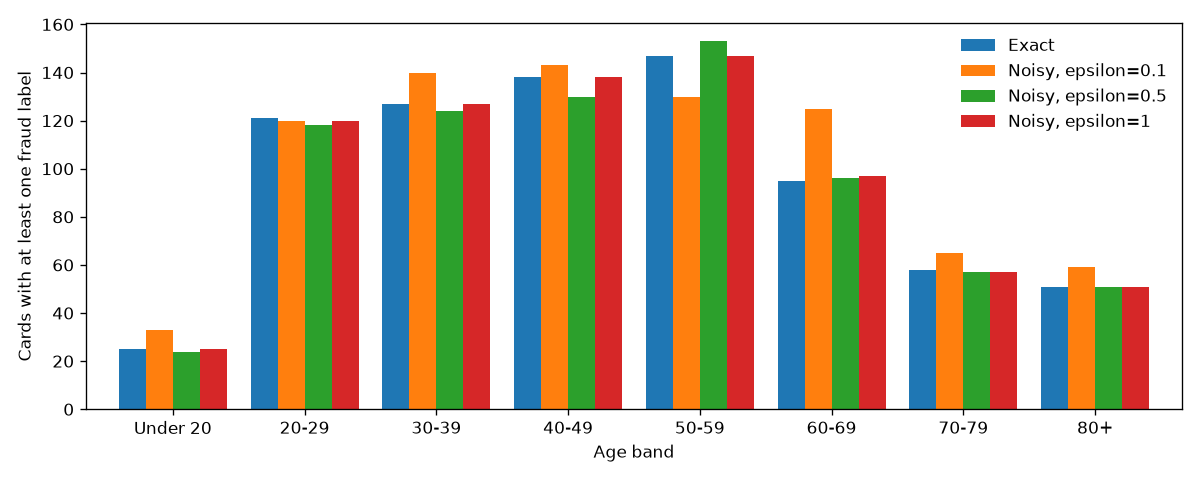

The smallest band (Under 20) has 25 cards, and the largest (50-59) has 147.
Mean absolute error falls from 9.97 cards per band at epsilon 0.1 to 0.96 at epsilon 1.


In [3]:
ax = comparison.plot.bar(figsize=(10, 4), width=0.82, rot=0)
ax.set(xlabel="Age band", ylabel="Cards with at least one fraud label")
ax.legend(frameon=False)
ax.figure.tight_layout()
plt.show()

smallest_band = exact_counts.idxmin()
largest_band = exact_counts.idxmax()
print(
    f"The smallest band ({smallest_band}) has {exact_counts.min()} cards, "
    f"and the largest ({largest_band}) has {exact_counts.max()}."
)
print(
    f"Mean absolute error falls from {summary.iloc[0, 0]:.2f} cards per band "
    f"at epsilon {epsilons[0]:g} to {summary.iloc[-1, 0]:.2f} "
    f"at epsilon {epsilons[-1]:g}."
)

The chart shows one draw per budget. The error table summarizes 5,000 draws per budget. Each band receives noise at the same scale, so a shift of a few cards matters more for a small band. The chart shows counts of affected cards. Estimating a fraud rate would also require denominators and a privacy budget for releasing them.